<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/HybridCVQNN_IntrusionDetection_Chao2023.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid continuous-variable quantum neural network (HCVQNN) for network intrusion detection: Chao et al. 2023 step by step

This notebook re-implements, runs and checks the experiments of

> S. Chao, G. Yang and M. Nie, "Hybrid Continuous Variational Quantum Neural Networks for Network Intrusion Detection,"
> in *Industrial Engineering and Applications* (ed. L.-C. Tang), Advances in Transdisciplinary Engineering vol. 36, IOS Press, 2023, pp. 366-378.
> https://doi.org/10.3233/ATDE230062

**What the paper does.** It proposes the **HCVQNN**: a 1-D convolutional network (two Conv1D + max-pool blocks, two dense layers) whose output is fed into a
**continuous-variable (CV) quantum neural network** with two layers. Each CV layer applies *Gaussian* gates (beamsplitter/rotation interferometer, squeezing,
a second interferometer, displacement), which act like a weight matrix and a bias, followed by a *non-Gaussian* gate (cubic phase) that plays the role of the activation function.
Because the UNSW-NB15 data are strongly imbalanced, the authors select features with **ReliefF** and rebalance the classes with **Borderline-SMOTE** (minority classes) and
**Gaussian-mixture clustering undersampling** (majority classes). They compare HCVQNN with a plain CNN and a CV-only network (CVQNN) for binary (normal vs attack) and
10-class classification and report HCVQNN as best (94.27 % binary and 87.66 % 10-class accuracy, Tables II and III).

**What this notebook does.**
1. downloads the official UNSW-NB15 training and testing partitions from a public Hugging Face mirror;
2. encodes the 39 numeric and 3 categorical columns, selects 32 features with a from-scratch **ReliefF**, and balances the *training* split with **GMM undersampling + Borderline-SMOTE** (every transform fitted on training data only);
3. shows the real data: class counts, a labelled 2-D projection of real flows, the ReliefF weights;
4. simulates the **CV layer in a truncated Fock space with PyTorch** (differentiable, so the whole hybrid network trains end to end; Strawberry Fields is not needed), checks the simulator against PennyLane's `default.gaussian` device, and draws the executed circuit with `qml.draw_mpl`;
5. trains CNN, CVQNN, HCVQNN and a classical control (CNN with a classical dense block instead of the CV layers) for the binary and the 10-class task, plus Random Forest and RBF-SVM on the identical 32 inputs;
6. redraws the paper's accuracy/loss curves (Figs. 4, 5, 7, 8), per-class detection (Figs. 6, 9) and Tables II and III next to the paper's numbers, with a verdict per claim.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. No GPU, no quantum hardware and no account are needed.
**Committed version: `FAST_MODE = True`, executed once from top to bottom (one seed, 6,000 balanced training flows, 12 epochs per model; about 60 minutes on a heavily shared single CPU thread, much less on an idle Colab CPU).** For a quick class demo reduce `PER_CLASS` and `EPOCHS` further. Setting `FAST_MODE = False` switches to the larger budgets below (not executed for the committed notebook because it would take several hours on a CPU simulator):

| budget | FAST_MODE = True (committed) | FAST_MODE = False |
|---|---|---|
| ReliefF reference instances / neighbour pool per class | 40 / 800 | 150 / 2000 |
| training flows per class after balancing (`PER_CLASS`) | 600 | 2500 |
| epochs | 12 | 20 |
| model seeds | 1 | 3 (mean +/- std) |
| Random-forest trees / SVC training flows | 100 / 3000 | 300 / 8000 |
| pooled random-split repetition | skipped | run (1 seed) |

**What you get at the end.** A table with the paper's and this notebook's numbers for every model and metric, per-claim verdicts, and an honest reading of what the CV layer does and does not add.

## The paper in one page

**Problem.** Network intrusion detection on UNSW-NB15 (binary: normal vs attack; multi-class: Normal + nine attack families), with a quantum neural network that is cheaper and more expressive than a classical one.

**Method (Section 3, Fig. 1-3, Table I).** Classical front end: Conv1D(128) - MaxPool(10, stride 2) - Conv1D(64) - MaxPool(5, stride 2) - Flatten - Dropout(0.6) - Dense(28, ELU) - Dense(14, ELU).
Quantum back end: two CVQNN layers on 2 qumodes. One layer = interferometer `U1(theta, phi)`, squeezing `S(r)`, interferometer `U2`, displacement `D(alpha)`, non-Gaussian gate `mu(lambda) = exp(i lambda x^3 / 3)` (the cubic phase gate, Eq. 9). A softmax layer gives the class (10 outputs for the multi-class task; for the binary task the non-Gaussian output alone is used).
Classical data enter the CV network through Gaussian gates (displacement). Training is end to end.

**Imbalance handling (Section 2).** ReliefF feature selection; Borderline-SMOTE to oversample the four minority classes (Analysis, Backdoor, Shellcode, Worms); GMM clustering to undersample majority classes.

**Claims we can test.**

| Id | Claim | Where |
|---|---|---|
| B1 | Binary: CNN 92.70 / 97.39 / 90.50 / 93.82, CVQNN 93.58 / 97.38 / 92.08 / 94.65, HCVQNN 94.27 / 98.36 / 98.62 / 95.68 (accuracy / precision / recall / F1, %) | Table II |
| M1 | 10-class: CNN 81.34 / 78.99 / 81.34 / 79.18, CVQNN 83.75 / 84.67 / 83.75 / 82.59, HCVQNN 87.66 / 88.76 / 87.66 / 86.29 (accuracy / weighted precision / recall / F1, %) | Table III |
| R1 | Ranking HCVQNN > CVQNN > CNN in accuracy, binary and 10-class | Figs. 4, 7 |
| C1 | HCVQNN converges fastest and reaches the lowest loss | Figs. 4, 5, 7, 8 |
| D1 | Per-class detection: improved on the rare attacks, no class has detection rate 0 | Figs. 6, 9 |
| P1 | The CV layer reduces parameters / computing time versus a classical network (abstract) | Abstract |

Paper numbers were transcribed from the PDF text of Tables II and III. Note that Table II's HCVQNN row is internally inconsistent: F1 = 95.68 cannot follow from precision 98.36 and recall 98.62 (their harmonic mean is 98.49); see the critical section.

### What follows the paper and what had to be chosen

The paper gives the layer list and the gate types but no sample sizes, split, number of selected features, optimiser, epochs, learning rate, circuit parameters, cutoff or simulator. No code is published. Each choice is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Data | UNSW-NB15 | UNSW-NB15 official training (175,341) and testing (82,332) partitions; a second run uses a pooled 70/30 random split because the paper does not say which split it used |
| Features | ReliefF subset (size not given) | One-hot protocol/service/state + 39 log1p numeric columns, 32 best by a class-balanced ReliefF (k = 10) |
| Balancing | Borderline-SMOTE + GMM, applied before training (not stated whether before the split) | Same two algorithms, applied to the **training** split only; test and validation flows keep the natural class distribution |
| CNN | Table I (kernel size missing) | Kernel size 3, "same" padding, pooling windows 10 and 5 with stride 2 as in Table I |
| CV layer | Gaussian gates + non-Gaussian gate, 2 modes | 2 modes, interferometer-squeezing-interferometer-displacement-cubic phase as in Fig. 1; one Re/Im displacement pair per mode encodes the 14 dense outputs through a linear 14 -> 4 layer |
| Simulator | not stated | Truncated Fock space (cutoff 10) in PyTorch, validated against PennyLane `default.gaussian` |
| Read-out | not stated | <x>, <p>, <n> of both modes (6 numbers) -> softmax layer (2 outputs binary, 10 multi-class) |
| Optimiser | not stated | Adam, learning rate 3e-3, batch 512, class-weighted cross-entropy |
| Epochs, seeds | curves to ~tens of iterations | see configuration cell |
| Metrics | accuracy, precision, recall, F1 (weighted for 10 classes: recall equals accuracy in Table III) | same, binary with attack as the positive class |

In [1]:
import sys, subprocess, importlib
IN_COLAB = "google.colab" in sys.modules
def _need(mod):
    try:
        importlib.import_module(mod); return False
    except Exception:
        return True
# Versions tested for this notebook. torch, numpy, pandas, scikit-learn and matplotlib already ship with Colab.
if IN_COLAB or _need("pennylane") or _need("imblearn") or _need("huggingface_hub"):
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1", "imbalanced-learn==0.14.2", "huggingface_hub"], check=False)
    print("Installed pennylane / imbalanced-learn. If an import error follows, use Runtime -> Restart session and run again.")
else:
    print("All required packages are already available.")

All required packages are already available.


In [2]:
# ---------------------------- configuration: every tunable constant lives here ----------------------------
SEED = 42
FAST_MODE = True                 # True: short demo (small budgets); False: the larger budgets below

# data
DATA_DIR = "unsw_nb15"          # downloaded files are cached here
LOCAL_TRAIN = ""                # optional: path to your own copy of the official training set (csv or parquet)
LOCAL_TEST  = ""                # optional: path to your own copy of the official testing set
VAL_FRAC = 0.10                 # share of the training flows held out for the learning curves (never used for fitting)

# preprocessing (all fitted on the training split only)
N_FEAT = 32                     # CHOICE: ReliefF keeps 32 features (one position per Conv1D step)
RELIEF_K = 10                   # nearest hits / misses per class
RELIEF_M_PER_CLASS = 40         # ReliefF reference instances per class
RELIEF_POOL_PER_CLASS = 800      # neighbours are searched among this many random flows per class
PER_CLASS = 600                  # CHOICE: every class is brought to this many training flows (GMM undersampling / Borderline-SMOTE)
GMM_K = 6                       # Gaussian-mixture components per undersampled class

# CV quantum layer (truncated Fock simulation)
CUTOFF = 10                     # CHOICE: Fock cutoff per mode (Hilbert space dimension 10 x 10 = 100)
ALPHA_MAX = 0.9                 # CHOICE: encoder output is squashed with tanh to |Re alpha|, |Im alpha| <= ALPHA_MAX (keeps the state inside the cutoff)
NONGAUSSIAN = "cubic"           # "cubic" = the paper's mu(lambda) = exp(i lambda x^3 / 3); "kerr" = Killoran et al.'s Kerr gate

# training
EPOCHS = 12
BATCH = 512
LR = 3e-3
SEEDS = [42]                      # model seeds; mean +/- std over them
SVC_MAX = 3000                    # SVC(rbf) is trained on at most this many of the (identical) balanced training flows
RF_TREES = 100
RUN_RANDOM_PROTOCOL = False        # also repeat everything on a pooled random 70/30 split (sensitivity check)
RANDOM_PROTOCOL_SEEDS = [42]
MODELS = ["cnn", "cnn_cls", "cvqnn", "hcvqnn"]

In [3]:
import os, time, warnings, math
warnings.filterwarnings("ignore")
os.environ.setdefault("OMP_NUM_THREADS", "1")
import numpy as np, pandas as pd
import matplotlib; matplotlib.rcParams["figure.dpi"] = 80
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import sklearn, pennylane as qml, imblearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, recall_score, confusion_matrix)
from imblearn.over_sampling import BorderlineSMOTE, SMOTE

torch.set_num_threads(1)                 # one thread: the models are tiny and the machine may be shared
np.random.seed(SEED); torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
NOTEBOOK_T0 = time.time()

# Hugging Face token: only needed if a gated mirror is used. In Colab put your own token under Settings > Secrets > HF_TOKEN.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

print("numpy %s | pandas %s | scikit-learn %s | imbalanced-learn %s | torch %s | pennylane %s" %
      (np.__version__, pd.__version__, sklearn.__version__, imblearn.__version__, torch.__version__, qml.__version__))
print("FAST_MODE =", FAST_MODE, "| SEED =", SEED)

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | imbalanced-learn 0.14.2 | torch 2.14.1+cpu | pennylane 0.45.1
FAST_MODE = True | SEED = 42


## 1. Data: the UNSW-NB15 training and testing partitions

UNSW-NB15 (Moustafa and Slay, MilCIS 2015, UNSW Canberra) contains network flows from a synthetic Cyber Range Lab. Each flow has 42 features (durations, packet and byte counts, TTLs, loads, jitter, window sizes, round-trip times, connection-count statistics, protocol, service, state), a binary label and one of **ten categories: Normal plus nine attack families** (Generic, Exploits, Fuzzers, DoS, Reconnaissance, Analysis, Backdoor, Shellcode, Worms). The four rarest (Analysis, Backdoor, Shellcode, Worms) are the "minority classes" of the paper.

The authors of the data set publish an official **training partition** (175,341 flows) and **testing partition** (82,332 flows); the paper does not say which flows it used. The files come from the public Hugging Face mirror `research-simulation26/unsw-nb15-parquet`; if it is unreachable the code falls back to `Mireu-Lab/UNSW-NB15` (whose train/test file names are swapped, and are swapped back). The data are not gated; a Hugging Face token is only used if the environment provides one (in Colab it would be read from *Secrets*, never typed into the notebook).

In [4]:
HF_REPO_MAIN = "research-simulation26/unsw-nb15-parquet"   # training_set.parquet (175,341 rows), testing_set.parquet (82,332 rows)
HF_REPO_ALT  = "Mireu-Lab/UNSW-NB15"                       # fallback: its train.csv holds the official TESTING set, test.csv the official TRAINING set
RENAME = {"smean": "smeansz", "dmean": "dmeansz", "response_body_len": "res_bdy_len", "sinpkt": "sintpkt", "dinpkt": "dintpkt"}

def tidy(df):
    df = df.copy()
    df.columns = [c.strip().lower() for c in df.columns]
    df = df.rename(columns=RENAME).drop(columns=["id"], errors="ignore")
    df["attack_cat"] = df["attack_cat"].astype(str).str.strip().replace({"Backdoors": "Backdoor", "": "Normal", "-": "Normal", "nan": "Normal"})
    for c in ("proto", "service", "state"):
        df[c] = df[c].astype(str).str.strip()
    return df

def read_any(path):
    return pd.read_parquet(path) if str(path).endswith(".parquet") else pd.read_csv(path, low_memory=False)

def load_unsw():
    if LOCAL_TRAIN and LOCAL_TEST:
        return tidy(read_any(LOCAL_TRAIN)), tidy(read_any(LOCAL_TEST))
    from huggingface_hub import hf_hub_download
    try:
        d = os.path.join(DATA_DIR, "main")
        tr = hf_hub_download(HF_REPO_MAIN, "training_set.parquet", repo_type="dataset", local_dir=d, token=HF_TOKEN)
        te = hf_hub_download(HF_REPO_MAIN, "testing_set.parquet", repo_type="dataset", local_dir=d, token=HF_TOKEN)
        print("loaded from", HF_REPO_MAIN)
        return tidy(read_any(tr)), tidy(read_any(te))
    except Exception as e:
        print("primary mirror failed (%s) -> fallback %s (file names swapped)" % (e.__class__.__name__, HF_REPO_ALT))
        d = os.path.join(DATA_DIR, "alt")
        a = hf_hub_download(HF_REPO_ALT, "test.csv", repo_type="dataset", local_dir=d, token=HF_TOKEN)
        b = hf_hub_download(HF_REPO_ALT, "train.csv", repo_type="dataset", local_dir=d, token=HF_TOKEN)
        return tidy(read_any(a)), tidy(read_any(b))

TRAIN_DF, TEST_DF = load_unsw()
CLASSES = ["Normal", "Generic", "Exploits", "Fuzzers", "DoS", "Reconnaissance", "Analysis", "Backdoor", "Shellcode", "Worms"]
MINORITY = ["Analysis", "Backdoor", "Shellcode", "Worms"]          # the four classes the paper calls minority classes
CLS_ID = {c: i for i, c in enumerate(CLASSES)}
for df in (TRAIN_DF, TEST_DF):
    assert set(df["attack_cat"]) == set(CLASSES), set(df["attack_cat"]) ^ set(CLASSES)
    assert df.drop(columns=["attack_cat", "proto", "service", "state"]).isna().sum().sum() == 0
print("official training partition:", TRAIN_DF.shape, "  official testing partition:", TEST_DF.shape)

loaded from research-simulation26/unsw-nb15-parquet


official training partition: (175341, 44)   official testing partition: (82332, 44)


## 2. Feature engineering, ReliefF and class balancing

Everything below is **fitted on the training split only**:

1. a validation set (10 % of the training flows, natural class distribution) is held out for the learning curves;
2. categorical columns are one-hot encoded, numeric columns get `log1p`, constant columns are dropped;
3. **ReliefF** (Eq. 1-2 of the paper, written from scratch; reference instances are drawn class-balanced, so the rare classes shape the selection) keeps the 32 best columns;
4. the 32 columns are standardised and clipped to [-5, 5];
5. the **training** flows are rebalanced to `PER_CLASS` flows per class: majority classes are undersampled by fitting a Gaussian mixture and drawing flows from each component in proportion to its size (GMM clustering undersampling), minority classes are oversampled with **Borderline-SMOTE** (borderline-1, k = 5, m = 10).

The test flows keep the **natural** class distribution (the quantity that matters in operation).

In [5]:
# ---------------- feature encoding (fitted on the training split only) ----------------
class Featurizer:
    def fit(self, df):
        self.num = [c for c in df.columns if c not in ("attack_cat", "label", "proto", "service", "state")]
        self.levels = {"proto": list(df["proto"].value_counts().index[:8]),       # CHOICE: top-8 protocols + "other"
                       "service": list(df["service"].value_counts().index),        # all services seen in training
                       "state": list(df["state"].value_counts().index[:6])}        # CHOICE: top-6 states + "other"
        self.cols = list(self.num)
        for c, lv in self.levels.items():
            self.cols += ["%s=%s" % (c, l) for l in lv] + (["%s=other" % c] if c != "service" else [])
        X = self.raw(df)
        self.keep = X.std(0) > 1e-9                                                  # drop constant columns
        self.cols = [c for c, k in zip(self.cols, self.keep) if k]
        return self
    def raw(self, df):
        blocks = [np.log1p(np.clip(df[self.num].to_numpy(float), 0, None))]         # CHOICE: log1p tames the heavy-tailed counters
        for c, lv in self.levels.items():
            v = df[c].to_numpy()[:, None]
            oh = (v == np.array(lv)[None, :])
            blocks.append(oh.astype(float))
            if c != "service":
                blocks.append((~oh.any(1, keepdims=True)).astype(float))
        return np.hstack(blocks)
    def transform(self, df):
        return self.raw(df)[:, self.keep].astype(np.float32)

# ---------------- ReliefF (Kononenko's multi-class version, Eq. 1-2 of the paper) ----------------
def relieff(X, y, n_classes, m_per_class, pool_per_class, k, rng):
    """X in [0,1]. Instances R are drawn class-balanced (m_per_class each); hits and misses are searched among a random
    pool of pool_per_class instances per class with the L1 distance; the class prior is therefore uniform."""
    d = X.shape[1]
    pools = []
    for c in range(n_classes):
        ic = np.flatnonzero(y == c)
        pools.append(torch.as_tensor(X[rng.choice(ic, min(len(ic), pool_per_class), replace=False)]))
    W = np.zeros(d); m_total = 0
    prior = 1.0 / n_classes
    for c in range(n_classes):
        ic = np.flatnonzero(y == c)
        sel = rng.choice(ic, min(len(ic), m_per_class), replace=False)
        R = torch.as_tensor(X[sel]); m_total += len(sel)
        for c2 in range(n_classes):
            P = pools[c2]
            dist = torch.cdist(R, P, p=1)
            kk = min(k + (1 if c2 == c else 0), len(P))
            nn_idx = dist.topk(kk, largest=False).indices
            if c2 == c:
                nn_idx = nn_idx[:, 1:]                                     # drop the instance itself
                W -= (R[:, None, :] - P[nn_idx]).abs().mean(1).sum(0).numpy()
            else:
                W += prior / (1 - prior) * (R[:, None, :] - P[nn_idx]).abs().mean(1).sum(0).numpy()
    return W / m_total

# ---------------- class balancing: GMM clustering undersampling + Borderline-SMOTE oversampling ----------------
def balance(X, y, per_class, seed, gmm_k):
    rng = np.random.default_rng(seed)
    parts, ys = [], []
    for c in range(len(CLASSES)):
        Xc = X[y == c]
        if len(Xc) > per_class:                                            # majority class -> keep per_class flows, spread over GMM clusters
            gm = GaussianMixture(n_components=gmm_k, covariance_type="diag", reg_covar=1e-4, max_iter=60, random_state=seed).fit(Xc)
            lab = gm.predict(Xc)
            cnt = np.bincount(lab, minlength=gmm_k)
            share = cnt / cnt.sum() * per_class
            alloc = np.minimum(np.floor(share).astype(int), cnt)
            for j in np.argsort(-(share - alloc)):
                if alloc.sum() < per_class and alloc[j] < cnt[j]:
                    alloc[j] += 1
            idx = np.concatenate([rng.choice(np.flatnonzero(lab == j), alloc[j], replace=False) for j in range(gmm_k)])
            if len(idx) < per_class:
                idx = np.concatenate([idx, rng.choice(np.setdiff1d(np.arange(len(Xc)), idx), per_class - len(idx), replace=False)])
            Xc = Xc[idx]
        parts.append(Xc); ys.append(np.full(len(Xc), c))
    Xb, yb = np.vstack(parts), np.concatenate(ys)
    n_real = len(yb)
    need = {c: per_class for c in range(len(CLASSES)) if (yb == c).sum() < per_class}
    if need:                                                              # minority class -> Borderline-SMOTE up to per_class
        try:
            Xb, yb = BorderlineSMOTE(sampling_strategy=need, k_neighbors=5, m_neighbors=10, kind="borderline-1", random_state=seed).fit_resample(Xb, yb)
        except Exception as e:
            print("   Borderline-SMOTE failed (%s); falling back to plain SMOTE" % e.__class__.__name__)
            Xb, yb = SMOTE(sampling_strategy=need, k_neighbors=5, random_state=seed).fit_resample(Xb, yb)
    is_synth = np.arange(len(yb)) >= n_real                               # imblearn appends the synthetic flows at the end
    return Xb.astype(np.float32), yb, is_synth

# ---------------- the whole preprocessing for one protocol ----------------
def prepare(protocol, seed):
    t0 = time.time()
    if protocol == "official":
        tr, te = TRAIN_DF, TEST_DF                                          # the data set authors' own partitions
    else:                                                                   # CHOICE: pooled 257,673 flows, stratified 70/30 random split
        pool = pd.concat([TRAIN_DF, TEST_DF], ignore_index=True)
        tr, te = train_test_split(pool, test_size=0.30, stratify=pool["attack_cat"], random_state=seed)
    tr, va = train_test_split(tr, test_size=VAL_FRAC, stratify=tr["attack_cat"], random_state=seed)   # validation flows are never used for fitting
    ytr = tr["attack_cat"].map(CLS_ID).to_numpy(); yva = va["attack_cat"].map(CLS_ID).to_numpy(); yte = te["attack_cat"].map(CLS_ID).to_numpy()
    fz = Featurizer().fit(tr)
    Rtr, Rva, Rte = fz.transform(tr), fz.transform(va), fz.transform(te)
    mm = MinMaxScaler().fit(Rtr)
    rng = np.random.default_rng(seed)
    w = relieff(np.clip(mm.transform(Rtr), 0, 1).astype(np.float32), ytr, len(CLASSES), RELIEF_M_PER_CLASS, RELIEF_POOL_PER_CLASS, RELIEF_K, rng)
    sel = np.argsort(-w)[:N_FEAT]                                           # CHOICE: top N_FEAT features, ordered by ReliefF weight, form the 1-D "image" for the CNN
    sc = StandardScaler().fit(Rtr[:, sel])
    f = lambda R: np.clip(sc.transform(R[:, sel]), -5, 5).astype(np.float32)
    Xtr, Xva, Xte = f(Rtr), f(Rva), f(Rte)
    Xbal, ybal, is_synth = balance(Xtr, ytr, PER_CLASS, seed, GMM_K)
    P = dict(protocol=protocol, names=[fz.cols[i] for i in sel], relief_w=w, all_names=fz.cols, sel=sel,
             Xtr=Xtr, ytr=ytr, Xva=Xva, yva=yva, Xte=Xte, yte=yte, Xbal=Xbal, ybal=ybal, is_synth=is_synth,
             n_raw=(len(tr), len(va), len(te)), seconds=time.time() - t0)
    print("[%s] split train/val/test = %d / %d / %d flows; %d encoded columns -> %d ReliefF-selected; balanced training set %d flows (%d synthetic); %.0fs"
          % (protocol, len(tr), len(va), len(te), len(fz.cols), N_FEAT, len(ybal), is_synth.sum(), P["seconds"]))
    return P

In [6]:
P = prepare("official", SEED)
Xtr, ytr, Xva, yva, Xte, yte, Xbal, ybal = P["Xtr"], P["ytr"], P["Xva"], P["yva"], P["Xte"], P["yte"], P["Xbal"], P["ybal"]
print("selected features, best first:", P["names"])

[official] split train/val/test = 157806 / 17535 / 82332 flows; 68 encoded columns -> 32 ReliefF-selected; balanced training set 6000 flows (483 synthetic); 29s
selected features, best first: ['service=-', 'proto=udp', 'proto=other', 'service=dns', 'smeansz', 'proto=unas', 'service=http', 'ct_srv_dst', 'ct_dst_src_ltm', 'ct_srv_src', 'ct_src_ltm', 'ct_dst_sport_ltm', 'ct_src_dport_ltm', 'sttl', 'ct_dst_ltm', 'dmeansz', 'res_bdy_len', 'sbytes', 'dload', 'ct_state_ttl', 'rate', 'sload', 'dbytes', 'dttl', 'state=INT', 'sintpkt', 'dloss', 'dur', 'ct_flw_http_mthd', 'state=CON', 'dpkts', 'proto=sctp']


## Dataset Exploration and Visualisation

All plots below use real UNSW-NB15 flows coloured by their real ground-truth category. Synthetic SMOTE flows are never mixed into the real-data scatter plots; they appear only in the last figure, explicitly marked.

official training partition: (175341, 44) | official testing partition: (82332, 44)
42 raw feature columns:
['dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sintpkt', 'dintpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smeansz', 'dmeansz', 'trans_depth', 'res_bdy_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports']

binary label (label): 0 = normal, 1 = attack
        train   test
label               
1      119341  45332
0       56000  37000



original category labels (attack_cat):
                train   test
attack_cat                  
Normal          56000  37000
Generic         40000  18871
Exploits        33393  11132
Fuzzers         18184   6062
DoS             12264   4089
Reconnaissance  10491   3496
Analysis         2000    677
Backdoor         1746    583
Shellcode        1133    378
Worms             130     44


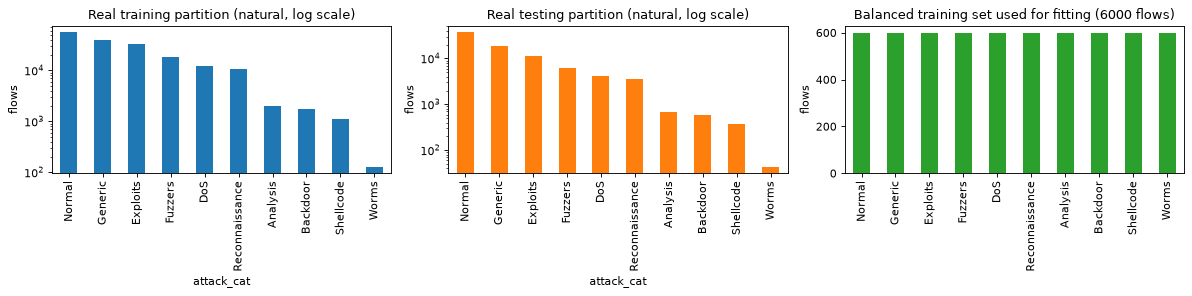

In [7]:
print("official training partition:", TRAIN_DF.shape, "| official testing partition:", TEST_DF.shape)
feat_cols = [c for c in TRAIN_DF.columns if c not in ("attack_cat", "label")]
print("%d raw feature columns:" % len(feat_cols)); print(feat_cols)
print("\nbinary label (label): 0 = normal, 1 = attack")
print(pd.DataFrame({"train": TRAIN_DF["label"].value_counts(), "test": TEST_DF["label"].value_counts()}))
cnt = pd.DataFrame({"train": TRAIN_DF["attack_cat"].value_counts(), "test": TEST_DF["attack_cat"].value_counts()}).reindex(CLASSES)
print("\noriginal category labels (attack_cat):"); print(cnt)
bal = pd.Series(np.bincount(ybal, minlength=10), index=CLASSES)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
cnt["train"].plot.bar(ax=ax[0], color="tab:blue", logy=True); ax[0].set_title("Real training partition (natural, log scale)")
cnt["test"].plot.bar(ax=ax[1], color="tab:orange", logy=True); ax[1].set_title("Real testing partition (natural, log scale)")
bal.plot.bar(ax=ax[2], color="tab:green"); ax[2].set_title("Balanced training set used for fitting (%d flows)" % len(ybal))
for a in ax: a.set_ylabel("flows")
plt.tight_layout(); plt.show()

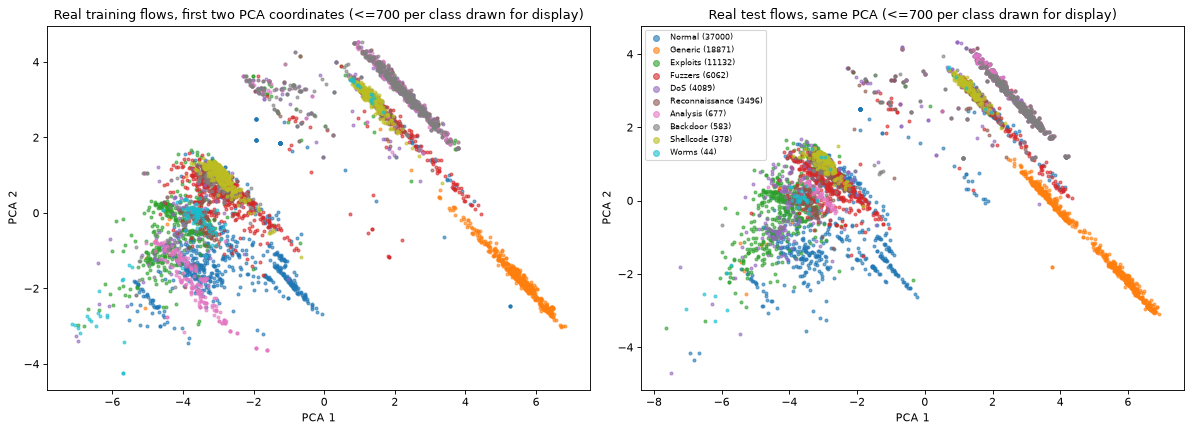

PCA explained variance (2 components): 58.2 %
The model does not use angle encoding: the CV layer receives learned displacements (see the latent-space plot after training).


In [8]:
COLORS = {c: plt.cm.tab10(i) for i, c in enumerate(CLASSES)}
def scatter(ax, Z, y, title, per_class=700, seed=0):
    r = np.random.default_rng(seed)
    for i, c in enumerate(CLASSES):
        ic = np.flatnonzero(y == i); ic = r.choice(ic, min(per_class, len(ic)), replace=False)
        ax.scatter(Z[ic, 0], Z[ic, 1], s=7, alpha=0.6, color=COLORS[c], label="%s (%d)" % (c, (y == i).sum()))
    ax.set_title(title); ax.set_xlabel("PCA 1"); ax.set_ylabel("PCA 2")
pca = PCA(n_components=2, random_state=SEED).fit(Xtr)                      # PCA fitted on the natural training split only
real_keep = ~P["is_synth"]
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
scatter(ax[0], pca.transform(Xtr), ytr, "Real training flows, first two PCA coordinates (<=700 per class drawn for display)")
scatter(ax[1], pca.transform(Xte), yte, "Real test flows, same PCA (<=700 per class drawn for display)")
ax[1].legend(fontsize=7, markerscale=2, loc="best")
plt.tight_layout(); plt.show()
print("PCA explained variance (2 components): %.1f %%" % (100 * pca.explained_variance_ratio_.sum()))
print("The model does not use angle encoding: the CV layer receives learned displacements (see the latent-space plot after training).")

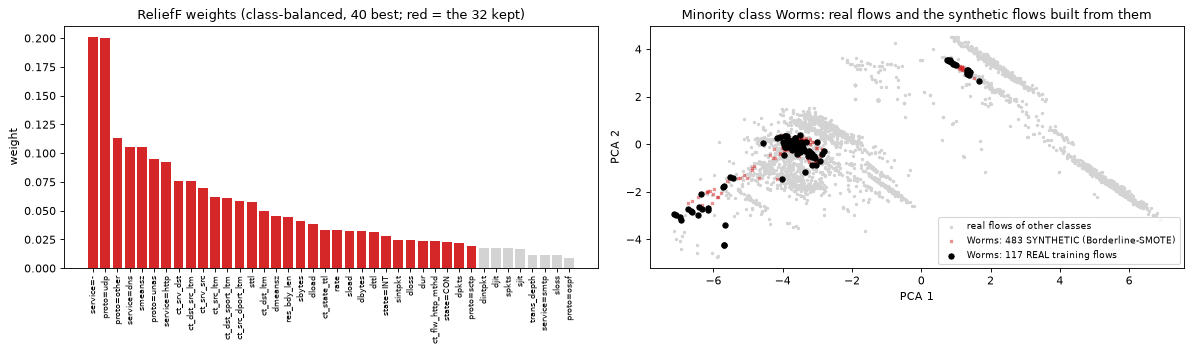

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
order = np.argsort(-P["relief_w"])[:40]
ax[0].bar(range(40), P["relief_w"][order], color=["tab:red" if i < N_FEAT else "lightgrey" for i in range(40)])
ax[0].set_xticks(range(40)); ax[0].set_xticklabels([P["all_names"][i] for i in order], rotation=90, fontsize=7)
ax[0].set_title("ReliefF weights (class-balanced, 40 best; red = the %d kept)" % N_FEAT); ax[0].set_ylabel("weight")
# Worms: the real flows against the Borderline-SMOTE flows that were created from them
iw = CLS_ID["Worms"]
real_w = Xbal[(ybal == iw) & ~P["is_synth"]]; syn_w = Xbal[(ybal == iw) & P["is_synth"]]
other = Xtr[ytr != iw]; other = other[np.random.default_rng(0).choice(len(other), 3000, replace=False)]
Zo, Zr, Zs = pca.transform(other), pca.transform(real_w), pca.transform(syn_w) if len(syn_w) else np.zeros((0, 2))
ax[1].scatter(Zo[:, 0], Zo[:, 1], s=4, color="lightgrey", label="real flows of other classes")
ax[1].scatter(Zs[:, 0], Zs[:, 1], s=6, marker="x", color="tab:red", alpha=0.5, label="Worms: %d SYNTHETIC (Borderline-SMOTE)" % len(syn_w))
ax[1].scatter(Zr[:, 0], Zr[:, 1], s=22, color="black", label="Worms: %d REAL training flows" % len(real_w))
ax[1].set_title("Minority class Worms: real flows and the synthetic flows built from them"); ax[1].legend(fontsize=8)
ax[1].set_xlabel("PCA 1"); ax[1].set_ylabel("PCA 2"); plt.tight_layout(); plt.show()

## 3. Classical baselines on the identical inputs

Random Forest and an RBF-SVM are trained on exactly the same 32 standardised features and the same balanced training set as the neural networks (the SVM on at most `SVC_MAX` of its flows, because kernel SVMs scale quadratically), and tested on the same natural-distribution test flows. This tells us how much of any accuracy is due to the data and the preprocessing rather than to the quantum layer.

In [10]:
def class_weights(y, K):
    n = np.bincount(y, minlength=K).astype(float)
    return (len(y) / (K * np.maximum(n, 1))).astype(np.float32)          # balanced-loss weights (all ~1 for the 10-class task)

def run_classical(Pr, seed):
    rows = []
    for task in ("binary", "multi"):
        ytr_t = (Pr["ybal"] > 0).astype(int) if task == "binary" else Pr["ybal"]
        yte_t = (Pr["yte"] > 0).astype(int) if task == "binary" else Pr["yte"]
        w = class_weights(ytr_t, 2 if task == "binary" else 10)[ytr_t]
        for name in ("rf", "svc"):
            t0 = time.time()
            if name == "rf":
                clf = RandomForestClassifier(n_estimators=RF_TREES, random_state=seed, n_jobs=1).fit(Pr["Xbal"], ytr_t, sample_weight=w)
            else:
                sub = np.random.default_rng(seed).choice(len(ytr_t), min(SVC_MAX, len(ytr_t)), replace=False)
                clf = SVC(kernel="rbf", C=10, gamma="scale", random_state=seed).fit(Pr["Xbal"][sub], ytr_t[sub], sample_weight=w[sub])
            pred = clf.predict(Pr["Xte"])
            m = metrics(yte_t, pred, task); m.update(task=task, model=name, seed=seed, train_s=time.time() - t0, params=np.nan, protocol=Pr["protocol"])
            rows.append(m)
    return rows

## 4. The continuous-variable layer, simulated in a truncated Fock space

**Why a custom simulator.** Continuous-variable circuits are normally run with Strawberry Fields, which is not available here and whose TensorFlow backend would make a hybrid network awkward. A CV circuit is a Gaussian-plus-cubic unitary acting on a harmonic-oscillator state, so for **2 modes** it can be simulated exactly up to a photon-number cutoff: each mode becomes a vector of `CUTOFF` Fock amplitudes, the 2-mode state has `CUTOFF^2 = 100` complex amplitudes, and every gate is a 100 x 100 unitary that PyTorch can differentiate. This is the same idea as the Fock backend of Strawberry Fields.

**Gates (hbar = 2, PennyLane convention, `x = a + a^dagger`).**
- Displacement `D(alpha) = exp(alpha a^dagger - alpha* a)`, squeezing `S(r) = exp(r (a^2 - a^dagger^2) / 2)`, rotation `R(phi) = exp(i phi n)`, beamsplitter `BS(theta, phi) = exp(theta (e^{i phi} a b^dagger - e^{-i phi} a^dagger b))`. Together they form the *Gaussian* part: interferometer `U1 = BS + 2 R`, squeezing, interferometer `U2`, displacement. These play the role of the weight matrix and bias.
- The *non-Gaussian* gate is the cubic phase gate `exp(i gamma x^3 / (3 hbar))` (paper Eq. 9), the nonlinearity.
- **Input encoding.** The 14 dense outputs go through a linear layer to 4 numbers `(Re alpha_1, Im alpha_1, Re alpha_2, Im alpha_2)` (squashed by `tanh` and scaled by `ALPHA_MAX`); the vacuum of each mode is displaced by `alpha_i`, i.e. each mode starts in a coherent state. This is the "Gaussian gate converts classical data to a quantum state" step of the paper.
- **Read-out.** Expectation values of `x`, `p` and the photon number of both modes (6 numbers) feed the final softmax layer (the paper does not specify the read-out).

**Truncation.** A cutoff makes every gate exactly unitary inside the truncated space, but the truncated gate is only a good approximation of the true gate while the state stays well below the cutoff. `ALPHA_MAX` bounds the input energy; the leakage into the highest Fock level is measured after training. The Beamsplitter conserves total photon number, so its exponential is computed block by block (cheap and exact).

In [11]:
CD, RD = torch.complex128, torch.float64
CS = torch.complex64                          # state vectors are propagated in single precision
N_MODES = 2          # the paper's table lists "CVQNN 2": two qumodes per CV layer

def expm_small(A, squarings=5, order=12):
    # exp(A) for small (batched) matrices by scaling and squaring + Horner-evaluated Taylor series.
    # Much cheaper (forward and backward) than torch.matrix_exp for 10x10 matrices; ||A|| < ~30 is covered.
    A = A / (2 ** squarings)
    I = torch.eye(A.shape[-1], dtype=A.dtype)
    P = I.expand_as(A)
    for k in range(order, 0, -1):
        P = I + (A @ P) / k
    for _ in range(squarings):
        P = P @ P
    return P

# ---- operators in a truncated Fock basis (hbar = 2, the PennyLane convention: x = a + a^dagger) ----
_a = torch.diag(torch.sqrt(torch.arange(1, CUTOFF, dtype=RD)), 1)          # annihilation operator, real
_I = torch.eye(CUTOFF, dtype=RD)
_nvec = torch.arange(CUTOFF, dtype=RD)
_ac = _a.to(CD)
_X = _ac + _ac.T                             # position quadrature x = a + a^dagger
_X3 = _X @ _X @ _X                           # cubic phase gate generator: exp(i*gamma*x^3 / (3*hbar)), hbar = 2
_sqrtn = torch.sqrt(torch.arange(1, CUTOFF, dtype=RD))

# Beamsplitter BS(theta, phi) = exp(theta (e^{i phi} a b^dag - e^{-i phi} a^dag b)) (PennyLane convention).
# It conserves the total photon number, so the 2-mode generator is block diagonal in n_a + n_b and
# BS(theta, phi) = R_b(phi) BS(theta, 0) R_b(phi)^dag, where BS(theta, 0) is the exponential of a real
# antisymmetric matrix. We exponentiate the (at most CUTOFF x CUTOFF) blocks only.
_a1, _a2 = torch.kron(_a, _I), torch.kron(_I, _a)
_C = _a1 @ _a2.T - _a1.T @ _a2
_idx = torch.arange(CUTOFF * CUTOFF)
_n1, _n2 = _idx // CUTOFF, _idx % CUTOFF
_sec = _n1 + _n2
_blk = torch.zeros((2 * CUTOFF - 1, CUTOFF), dtype=torch.long)
_msk = torch.zeros((2 * CUTOFF - 1, CUTOFF), dtype=torch.bool)
for _s in range(2 * CUTOFF - 1):
    _ii = _idx[_sec == _s]; _blk[_s, :len(_ii)] = _ii; _msk[_s, :len(_ii)] = True
_m2 = _msk[:, :, None] & _msk[:, None, :]
_Cb = _C[_blk[:, :, None], _blk[:, None, :]] * _m2
_flat = (_blk[:, :, None].expand(-1, -1, CUTOFF) * (CUTOFF * CUTOFF) + _blk[:, None, :].expand(-1, CUTOFF, -1))[_m2]
_padI = (~_msk)[:, :, None] * torch.eye(CUTOFF, dtype=RD)[None]
_dn2 = (_n2[:, None] - _n2[None, :]).to(RD)
_nvecs = [torch.kron(_nvec, torch.ones(CUTOFF, dtype=RD)), torch.kron(torch.ones(CUTOFF, dtype=RD), _nvec)]

def bs_unitary(theta, phi):
    Eb = expm_small(theta * _Cb) * _m2 + _padI
    U0 = torch.zeros(CUTOFF ** 4, dtype=RD).index_put((_flat,), Eb[_m2]).reshape(CUTOFF ** 2, CUTOFF ** 2)
    return U0.to(CD) * torch.exp(1j * phi * _dn2)

# The stage list below is the single source of truth: the Fock simulator builds the layer unitary from it
# and the PennyLane QNode that is drawn in the "Quantum Circuit Architecture" section is built from the same list.
LAYER_STAGES = [("BS", "int1"), ("R", "int1"), ("S",), ("BS", "int2"), ("R", "int2"), ("D",), ("NL",)]
LAYER_GATES = []                          # the same list written gate by gate (name, mode or interferometer tag)
for _st in LAYER_STAGES:
    if _st[0] == "BS": LAYER_GATES.append(("BS", _st[1]))
    elif _st[0] == "R": LAYER_GATES += [("R", 0, _st[1]), ("R", 1, _st[1])]
    else: LAYER_GATES += [(_st[0], 0), (_st[0], 1)]

class CVLayer(nn.Module):
    """One Killoran-style CV layer on 2 modes: interferometer, squeezing, interferometer, displacement, non-Gaussian gate."""
    def __init__(self, nongaussian="cubic", seed=0):
        super().__init__()
        g = torch.Generator().manual_seed(seed)
        def p(*shape, std=0.1): return nn.Parameter(torch.randn(*shape, generator=g, dtype=RD) * std)
        self.bs1, self.bs2 = p(2), p(2)             # (theta, phi) of the two interferometer beamsplitters
        self.rot1, self.rot2 = p(2), p(2)           # rotation angles of the two interferometers (one per mode)
        self.sq = p(2)                              # squeezing magnitudes r_i
        self.disp = p(2, 2)                         # displacement (Re alpha_i, Im alpha_i)
        self.nl = p(2, std=0.05)                    # cubic-phase gamma_i (or Kerr kappa_i)
        self.nongaussian = nongaussian
    def unitary(self, gaussian_only=False):
        U = torch.eye(CUTOFF ** 2, dtype=CD)
        for st in LAYER_STAGES:
            if st[0] == "BS":
                bs = self.bs1 if st[1] == "int1" else self.bs2
                U = bs_unitary(bs[0], bs[1]) @ U
            elif st[0] == "R":
                rot = self.rot1 if st[1] == "int1" else self.rot2
                U = torch.exp(1j * (rot[0] * _nvecs[0] + rot[1] * _nvecs[1]))[:, None] * U
            elif st[0] == "S":
                M = expm_small(0.5 * self.sq[:, None, None] * (_ac @ _ac - _ac.T @ _ac.T)[None])
                U = torch.kron(M[0], M[1]) @ U
            elif st[0] == "D":
                al = torch.complex(self.disp[:, 0], self.disp[:, 1])[:, None, None]
                M = expm_small(al * _ac.T[None] - al.conj() * _ac[None])
                U = torch.kron(M[0], M[1]) @ U
            elif st[0] == "NL" and not gaussian_only:
                if self.nongaussian == "cubic":
                    M = expm_small(1j * self.nl[:, None, None] * _X3[None] / 6.0)   # exp(i gamma x^3 / (3 hbar)), hbar = 2
                else:
                    M = torch.diag_embed(torch.exp(1j * self.nl[:, None] * _nvec[None] ** 2))   # Kerr: exp(i kappa n^2)
                U = torch.kron(M[0], M[1]) @ U
        return U

def coherent(alpha):
    # |alpha> in the truncated Fock basis, alpha: complex (B,) -> (B, CUTOFF), renormalised after truncation
    cs = [torch.ones_like(alpha)]
    for n in range(1, CUTOFF):
        cs.append(cs[-1] * alpha / float(np.sqrt(n)))
    c = torch.stack(cs, dim=1)
    c = c * torch.exp(-(alpha.real ** 2 + alpha.imag ** 2) / 2)[:, None]
    return c / torch.sqrt((c.real ** 2 + c.imag ** 2).sum(1, keepdim=True))

def encode(alpha2):
    # alpha2: complex (B, 2): displace each mode of the vacuum by alpha_i  ->  (B, CUTOFF^2)
    c0, c1 = coherent(alpha2[:, 0]), coherent(alpha2[:, 1])
    return torch.einsum("bi,bj->bij", c0, c1).reshape(-1, CUTOFF ** 2)

def readout(psi):
    # <x>, <p>, <n> on both modes  ->  (B, 6) real.  <a> = sum conj(psi_n) sqrt(n+1) psi_{n+1};  x = 2 Re<a>, p = 2 Im<a>
    s = psi.reshape(-1, CUTOFF, CUTOFF)
    pr = s.real ** 2 + s.imag ** 2
    a0 = (s[:, :-1, :].conj() * s[:, 1:, :] * _sqrtn.float()[None, :, None]).sum((1, 2))
    a1 = (s[:, :, :-1].conj() * s[:, :, 1:] * _sqrtn.float()[None, None, :]).sum((1, 2))
    n0 = (pr.sum(2) * _nvec.float()[None]).sum(1)
    n1 = (pr.sum(1) * _nvec.float()[None]).sum(1)
    return torch.stack([2 * a0.real, 2 * a1.real, 2 * a0.imag, 2 * a1.imag, n0, n1], dim=1)   # order x0 x1 p0 p1 n0 n1

In [12]:
def pool_same(x, k, s):
    # Keras-style MaxPooling1D(pool_size=k, strides=s, padding="same")
    L = x.shape[-1]
    out = -(-L // s)
    pad = max((out - 1) * s + k - L, 0)
    return F.max_pool1d(F.pad(x, (pad // 2, pad - pad // 2), value=float("-inf")), k, s)

class Net(nn.Module):
    """kind = 'cnn'      : paper's classical CNN (Table I without the CVQNN rows)
       kind = 'cnn_cls'  : CNN + the same 4-dim encoder, but a classical Dense block where the CV layers sit (control)
       kind = 'cvqnn'    : no CNN; the 32 selected features -> 4-dim encoder -> 2 CV layers -> softmax
       kind = 'hcvqnn'   : the paper's model: CNN -> Dense 28 -> Dense 14 -> 4-dim encoder -> 2 CV layers -> softmax"""
    def __init__(self, kind, n_feat, K, seed):
        super().__init__()
        self.kind = kind
        torch.manual_seed(seed)
        self.has_cnn = kind in ("cnn", "cnn_cls", "hcvqnn")
        width = n_feat
        if self.has_cnn:
            self.c1 = nn.Conv1d(1, 128, 3, padding="same")     # CHOICE: kernel size 3 (paper gives only the filter count)
            self.c2 = nn.Conv1d(128, 64, 3, padding="same")
            L1 = -(-n_feat // 2); L = -(-L1 // 2)               # length after two stride-2 'same' poolings
            self.drop = nn.Dropout(0.6)
            self.f1, self.f2 = nn.Linear(64 * L, 28), nn.Linear(28, 14)
            width = 14
        if kind == "cnn":
            self.head = nn.Linear(14, K)
        elif kind == "cnn_cls":
            self.enc = nn.Linear(14, 4)
            self.blk = nn.Sequential(nn.Linear(4, 4), nn.Tanh(), nn.Linear(4, 6), nn.Tanh())   # classical stand-in for 2 CV layers (6 outputs like the CV read-out)
            self.head = nn.Linear(6, K)
        else:
            self.enc = nn.Linear(width, 4)                      # CHOICE: Re/Im of the displacement of the 2 modes
            self.cv = nn.ModuleList([CVLayer(NONGAUSSIAN, seed=seed * 10 + i) for i in range(2)])
            self.head = nn.Linear(6, K)
    def trunk(self, x):
        if not self.has_cnn:
            return x
        h = x[:, None, :]
        h = pool_same(F.relu(self.c1(h)), 10, 2)
        h = pool_same(F.relu(self.c2(h)), 5, 2)
        h = self.drop(h.flatten(1))
        return F.elu(self.f2(F.elu(self.f1(h))))
    def alphas(self, x):
        z = torch.tanh(self.enc(self.trunk(x)))
        return ALPHA_MAX * torch.complex(z[:, [0, 2]], z[:, [1, 3]])        # complex displacement per mode, |Re|,|Im| <= ALPHA_MAX
    def forward(self, x):
        if self.kind == "cnn":
            return self.head(self.trunk(x))
        if self.kind == "cnn_cls":
            return self.head(self.blk(torch.tanh(self.enc(self.trunk(x)))))
        psi = encode(self.alphas(x))
        for U in [L.unitary().to(CS) for L in self.cv]:
            psi = psi @ U.T
        return self.head(readout(psi))

def n_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

@torch.no_grad()
def predict_logits(net, X, chunk=8192):
    net.eval()
    return torch.cat([net(torch.as_tensor(X[i:i + chunk])) for i in range(0, len(X), chunk)])

def fit(kind, Xtr, ytr, Xva, yva, K, seed, epochs, batch, lr, class_w, verbose=True):
    net = Net(kind, Xtr.shape[1], K, seed)
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    Xt, yt = torch.as_tensor(Xtr), torch.as_tensor(ytr)
    w = torch.as_tensor(class_w, dtype=torch.float32)
    g = torch.Generator().manual_seed(seed)
    Xv, yv = torch.as_tensor(Xva), torch.as_tensor(yva)
    hist = []; t0 = time.time()
    for ep in range(epochs):
        net.train(); perm = torch.randperm(len(Xt), generator=g); tl = tc = 0.0
        for i in range(0, len(perm), batch):
            b = perm[i:i + batch]
            out = net(Xt[b]); loss = F.cross_entropy(out, yt[b], weight=w)
            opt.zero_grad(); loss.backward(); opt.step()
            tl += loss.item() * len(b); tc += (out.argmax(1) == yt[b]).sum().item()
        lv = predict_logits(net, Xva)
        hist.append(dict(epoch=ep + 1, train_loss=tl / len(Xt), train_acc=tc / len(Xt),
                         val_loss=F.cross_entropy(lv, yv).item(), val_acc=(lv.argmax(1) == yv).float().mean().item()))
    if verbose:
        h = hist[-1]; print("   %-8s seed %d  %2d epochs  %5.0fs  train_loss %.3f  val_acc %.4f  (%d parameters)" % (kind, seed, epochs, time.time() - t0, h["train_loss"], h["val_acc"], n_params(net)))
    return net, hist, time.time() - t0

def metrics(y, pred, task):
    if task == "binary":
        p, r, f, _ = precision_recall_fscore_support(y, pred, average="binary", pos_label=1, zero_division=0)
    else:
        p, r, f, _ = precision_recall_fscore_support(y, pred, average="weighted", zero_division=0)
    out = dict(acc=100 * accuracy_score(y, pred), prec=100 * p, rec=100 * r, f1=100 * f)
    if task == "multi":
        out["recall_per_class"] = recall_score(y, pred, average=None, labels=list(range(len(CLASSES))), zero_division=0) * 100
    return out

In [13]:
for kind in MODELS:
    m = Net(kind, N_FEAT, 10, SEED)
    print("%-8s trainable parameters (10-class head): %6d" % (kind, n_params(m)))
print("\nCV layer parameters per layer:", sum(p.numel() for p in CVLayer().parameters()), "(2 beamsplitters x (theta, phi), 2 x 2 rotations, 2 squeezings, 2 complex displacements, 2 cubic-phase gammas)")

cnn      trainable parameters (10-class head):  40072
cnn_cls  trainable parameters (10-class head):  40102
cvqnn    trainable parameters (10-class head):    234
hcvqnn   trainable parameters (10-class head):  40084

CV layer parameters per layer: 16 (2 beamsplitters x (theta, phi), 2 x 2 rotations, 2 squeezings, 2 complex displacements, 2 cubic-phase gammas)


## Quantum Circuit Architecture

The CV block that is executed has **2 qumodes** (continuous-variable "wires") and two identical layers. The drawing below is made by `qml.draw_mpl` from a real PennyLane QNode on the `default.gaussian` device, built from the **same gate list (`LAYER_GATES`)** that the Fock simulator uses to build the unitary and with the **parameter values of an actual model on an actual test flow**. The QNode is built only to be drawn and to run the equivalence checks, because `default.gaussian` cannot execute the non-Gaussian cubic phase gate; the checks below therefore compare the Gaussian part against PennyLane numerically and test the cubic phase gate against its analytic action.

Notation in the drawing: `Displacement(r, phi)` is `D(alpha)` with `alpha = r e^{i phi}`; `Beamsplitter(theta, phi)`; `Rotation(phi)`; `Squeezing(r, 0)`; `CubicPhase(gamma)`. The first two gates on each wire are the data-encoding displacements of the vacuum. Measurements: `<x>`, `<p>`, photon number on both modes. There are no qubits; the Fock cutoff replaces the qubit count.

real test flow #0 (class Normal) -> input displacements alpha = [ 0.289-0.214j -0.088+0.23j ]


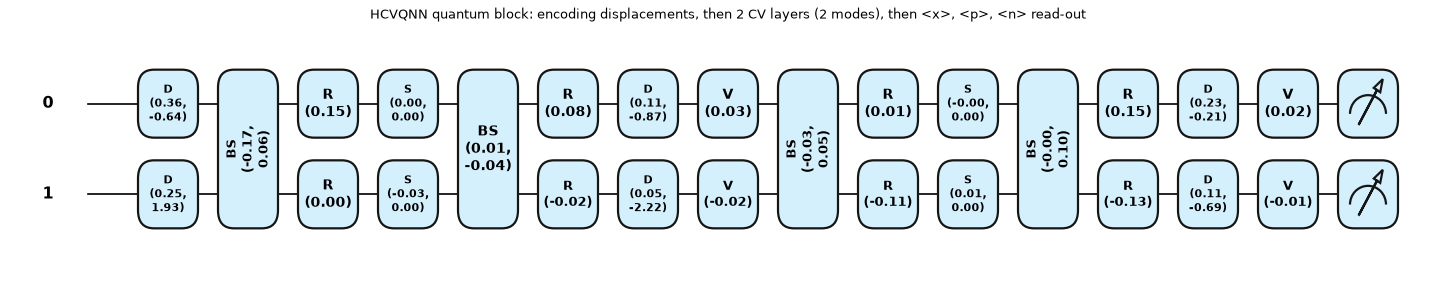

qumodes: 2   (qubits: 0 - continuous-variable circuit)   Fock cutoff per mode: 10   Hilbert-space dimension: 100
operations in the executed circuit: 26   circuit depth: 15
trainable CV-circuit parameters: 32  (16 per layer x 2 layers);  parameters of the whole HCVQNN (10-class head): 40084
gate sequence in one layer (from LAYER_GATES): ['BS', 'R0', 'R1', 'S0', 'S1', 'BS', 'R0', 'R1', 'D0', 'D1', 'NL0', 'NL1']


In [14]:
demo = Net("hcvqnn", N_FEAT, 10, SEED)
with torch.no_grad():
    alpha_demo = demo.alphas(torch.as_tensor(Xte[:1]))[0].numpy()          # displacement amplitudes the encoder produces for a real test flow
print("real test flow #0 (class %s) -> input displacements alpha = %s" % (CLASSES[yte[0]], np.round(alpha_demo, 3)))

def apply_cv(alpha, layers, gaussian_only=False):
    # the PennyLane circuit, generated from the same LAYER_GATES list as the Fock simulator
    for m in range(2):
        qml.Displacement(float(abs(alpha[m])), float(np.angle(alpha[m])), wires=m)
    for layer in layers:
        for g in LAYER_GATES:
            if g[0] == "BS":
                bs = (layer.bs1 if g[1] == "int1" else layer.bs2).detach().numpy()
                qml.Beamsplitter(float(bs[0]), float(bs[1]), wires=[0, 1])
            elif g[0] == "R":
                rot = (layer.rot1 if g[2] == "int1" else layer.rot2).detach().numpy()
                qml.Rotation(float(rot[g[1]]), wires=g[1])
            elif g[0] == "S":
                qml.Squeezing(float(layer.sq[g[1]].detach()), 0.0, wires=g[1])
            elif g[0] == "D":
                d = layer.disp[g[1]].detach().numpy(); al = d[0] + 1j * d[1]
                qml.Displacement(float(abs(al)), float(np.angle(al)), wires=g[1])
            elif g[0] == "NL" and not gaussian_only:
                if layer.nongaussian == "cubic":
                    qml.CubicPhase(float(layer.nl[g[1]].detach()), wires=g[1])
                else:
                    qml.Kerr(float(layer.nl[g[1]].detach()), wires=g[1])

dev_cv = qml.device("default.gaussian", wires=2)
@qml.qnode(dev_cv)
def hcvqnn_block(alpha):
    apply_cv(alpha, list(demo.cv))
    return [qml.expval(qml.QuadX(0)), qml.expval(qml.QuadX(1)), qml.expval(qml.QuadP(0)), qml.expval(qml.QuadP(1)),
            qml.expval(qml.NumberOperator(0)), qml.expval(qml.NumberOperator(1))]

fig, ax = qml.draw_mpl(hcvqnn_block, level="top", decimals=2, style="pennylane")(alpha_demo)
fig.set_size_inches(min(fig.get_size_inches()[0], 22), 3.4); fig.suptitle("HCVQNN quantum block: encoding displacements, then 2 CV layers (2 modes), then <x>, <p>, <n> read-out", y=1.02)
plt.show()

tape = qml.workflow.construct_batch(hcvqnn_block, level="top")(alpha_demo)[0][0]
n_cv_params = sum(p.numel() for p in demo.cv.parameters())
print("qumodes: 2   (qubits: 0 - continuous-variable circuit)   Fock cutoff per mode:", CUTOFF, "  Hilbert-space dimension:", CUTOFF ** 2)
print("operations in the executed circuit:", len(tape.operations), "  circuit depth:", tape.graph.get_depth())
print("trainable CV-circuit parameters:", n_cv_params, " (16 per layer x 2 layers);  parameters of the whole HCVQNN (10-class head):", n_params(demo))
expected = 2 + 2 * len(LAYER_GATES)
assert len(tape.operations) == expected, (len(tape.operations), expected)       # the drawn tape contains exactly the gates of the simulator's gate list
print("gate sequence in one layer (from LAYER_GATES):", [g[0] + (str(g[1]) if g[0] != "BS" else "") for g in LAYER_GATES])

In [15]:
# Equivalence checks between the Fock simulator that is trained and PennyLane
def fock_expectations(alpha, layers, gaussian_only):
    with torch.no_grad():
        psi = encode(torch.as_tensor(alpha, dtype=CD)[None]).to(CS)
        for L in layers:
            psi = psi @ L.unitary(gaussian_only=gaussian_only).to(CS).T
        return readout(psi)[0].double().numpy()        # order: x0 x1 p0 p1 n0 n1

def pl_expectations(alpha, layers):
    out = []
    for obs in (qml.QuadX(0), qml.QuadX(1), qml.QuadP(0), qml.QuadP(1), qml.NumberOperator(0), qml.NumberOperator(1)):
        @qml.qnode(dev_cv)
        def f():
            apply_cv(alpha, layers, gaussian_only=True)
            return qml.expval(obs)
        out.append(float(f()))
    return np.array(out)

# (a) Gaussian part, untrained model, real test flows
errs = []
for i in range(3):
    with torch.no_grad():
        a = demo.alphas(torch.as_tensor(Xte[i:i + 1]))[0].numpy()
    errs.append(np.abs(fock_expectations(a, demo.cv, True) - pl_expectations(a, list(demo.cv))).max())
print("(a) Gaussian circuit, Fock simulator vs PennyLane default.gaussian, max |difference| over <x>,<p>,<n> and 3 real flows: %.2e" % max(errs))
assert max(errs) < 5e-3
# (b) the same with larger random parameters (stress test of the truncation: the error is expected to grow)
big = [CVLayer(seed=100 + i) for i in range(2)]
with torch.no_grad():
    for L in big:
        L.disp.mul_(2.0); L.sq.mul_(2.0)
a = np.array([0.7 * np.exp(0.4j), 0.5 * np.exp(-0.3j)])
e2 = np.abs(fock_expectations(a, big, True) - pl_expectations(a, big)).max()
print("(b) 2x larger squeezing/displacement (2 layers): max |difference| = %.2e  <- truncation error at higher energy (cutoff %d); this is why ALPHA_MAX bounds the input energy" % (e2, CUTOFF)); assert e2 < 0.2
# (c) unitarity of the layer
Uchk = demo.cv[0].unitary().detach()
print("(c) layer unitarity  max|U^dagger U - 1| = %.1e" % (Uchk.conj().T @ Uchk - torch.eye(CUTOFF ** 2)).abs().max().item())
# (d) the non-Gaussian cubic phase gate against its analytic action  V^dagger p V = p + gamma x^2  (small gamma)
g0 = 0.02
psi0 = encode(torch.tensor([[0.6 + 0.2j, 0.4 - 0.3j]], dtype=CD))[0]
Vx = torch.matrix_exp(1j * g0 * _X3 / 6.0); V = torch.kron(Vx, torch.eye(CUTOFF, dtype=CD)); psiV = V @ psi0
OPp = torch.kron(-1j * (_ac - _ac.T), torch.eye(CUTOFF, dtype=CD)); OPx2 = torch.kron(_X @ _X, torch.eye(CUTOFF, dtype=CD))
ev = lambda O, s: (s.conj() @ O @ s).real.item()
print("(d) cubic phase: <p> shift = %.5f   analytic gamma*<x^2> = %.5f" % (ev(OPp, psiV) - ev(OPp, psi0), g0 * ev(OPx2, psi0)))
assert abs((ev(OPp, psiV) - ev(OPp, psi0)) - g0 * ev(OPx2, psi0)) < 2e-3
print("All equivalence checks passed.")

(a) Gaussian circuit, Fock simulator vs PennyLane default.gaussian, max |difference| over <x>,<p>,<n> and 3 real flows: 1.81e-07
(b) 2x larger squeezing/displacement (2 layers): max |difference| = 4.53e-02  <- truncation error at higher energy (cutoff 10); this is why ALPHA_MAX bounds the input energy


(c) layer unitarity  max|U^dagger U - 1| = 2.1e-14
(d) cubic phase: <p> shift = 0.04880   analytic gamma*<x^2> = 0.04880
All equivalence checks passed.


## 5. Training the networks

Four neural models are trained on exactly the same 32 inputs (the CNN-based ones see them as a 1-D sequence):

| name in the code | what it is | paper counterpart |
|---|---|---|
| `cnn` | Table I without the CVQNN rows (Conv-Pool-Conv-Pool-Flatten-Dropout-Dense 28-Dense 14-softmax) | "CNN" |
| `cvqnn` | linear encoder 32 -> 4, two CV layers, softmax; no CNN | "CVQNN" |
| `hcvqnn` | the CNN trunk, linear 14 -> 4 encoder, two CV layers, softmax | "HCVQNN" |
| `cnn_cls` | **control**: the HCVQNN with a classical Dense(4)-tanh-Dense(6)-tanh block in place of the two CV layers | not in the paper |

The loss is a class-weighted cross-entropy (weights make the binary task balanced; the 10-class balanced set needs none). The learning curves use the 10 % validation flows with their natural class distribution; the test flows are used once, after the last epoch. For the binary task the labels are `attack_cat != Normal`.

In [16]:
def run_experiment(Pr, seeds):
    rows, hists, models = [], {}, {}
    Xb, yb = Pr["Xbal"], Pr["ybal"]
    for task in ("binary", "multi"):
        K = 2 if task == "binary" else 10
        f = (lambda y: (y > 0).astype(np.int64)) if task == "binary" else (lambda y: y.astype(np.int64))
        ytr_t, yva_t, yte_t = f(yb), f(Pr["yva"]), f(Pr["yte"])
        cw = class_weights(ytr_t, K)
        print("--- %s task (%s) ---" % (task, Pr["protocol"]))
        for kind in MODELS:
            for s in seeds:
                net, hist, secs = fit(kind, Xb, ytr_t, Pr["Xva"], yva_t, K, s, EPOCHS, BATCH, LR, cw)
                logits = predict_logits(net, Pr["Xte"]); pred = logits.argmax(1).numpy()
                m = metrics(yte_t, pred, task)
                va = np.array([h["val_acc"] for h in hist])
                m.update(task=task, model=kind, seed=s, train_s=secs, params=n_params(net), protocol=Pr["protocol"],
                         plateau_epoch=int(np.argmax(va >= va[-1] - 0.01) + 1), final_train_loss=hist[-1]["train_loss"],
                         cm=confusion_matrix(yte_t, pred, labels=list(range(K))))
                rows.append(m); hists.setdefault((task, kind), []).append(hist)
                if s == seeds[0]: models[(task, kind)] = net
    for s in seeds:
        rows += run_classical(Pr, s)
    return pd.DataFrame(rows), hists, models

t_train = time.time()
RES, HIST, MODELS_TRAINED = run_experiment(P, SEEDS)
print("\ntraining + evaluation of all models: %.1f min" % ((time.time() - t_train) / 60))

--- binary task (official) ---


   cnn      seed 42  12 epochs    392s  train_loss 0.210  val_acc 0.9182  (39952 parameters)


   cnn_cls  seed 42  12 epochs    313s  train_loss 0.258  val_acc 0.9126  (40046 parameters)


   cvqnn    seed 42  12 epochs     98s  train_loss 0.184  val_acc 0.9135  (178 parameters)


   hcvqnn   seed 42  12 epochs    529s  train_loss 0.239  val_acc 0.9105  (40028 parameters)


...

   cnn      seed 42  12 epochs    446s  train_loss 1.135  val_acc 0.6634  (40072 parameters)


   cnn_cls  seed 42  12 epochs    610s  train_loss 1.830  val_acc 0.5482  (40102 parameters)


   cvqnn    seed 42  12 epochs     52s  train_loss 1.373  val_acc 0.5824  (234 parameters)


   hcvqnn   seed 42  12 epochs    251s  train_loss 1.392  val_acc 0.6161  (40084 parameters)



training + evaluation of all models: 55.3 min


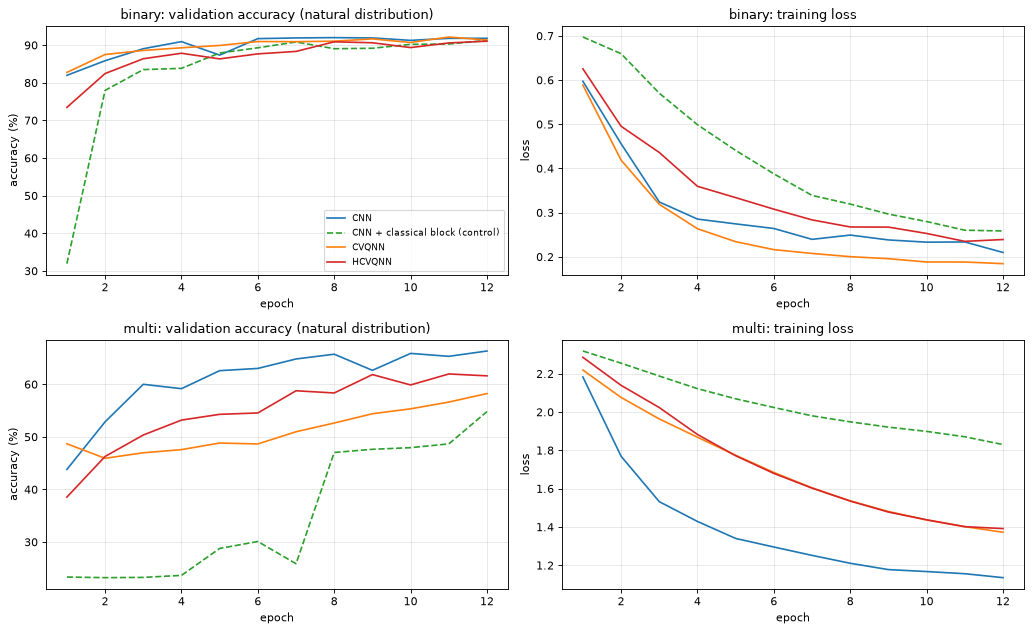

In [17]:
# Learning curves: the analogues of Figs. 4, 5 (binary) and 7, 8 (10-class)
NAMES = {"cnn": "CNN", "cvqnn": "CVQNN", "hcvqnn": "HCVQNN", "cnn_cls": "CNN + classical block (control)"}
STY = {"cnn": "tab:blue", "cvqnn": "tab:orange", "hcvqnn": "tab:red", "cnn_cls": "tab:green"}
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
for r, task in enumerate(("binary", "multi")):
    for kind in MODELS:
        H = HIST[(task, kind)]
        va = np.mean([[h["val_acc"] for h in hh] for hh in H], 0) * 100; tl = np.mean([[h["train_loss"] for h in hh] for hh in H], 0)
        ep = np.arange(1, len(va) + 1)
        ax[r, 0].plot(ep, va, color=STY[kind], label=NAMES[kind], ls="--" if kind == "cnn_cls" else "-")
        ax[r, 1].plot(ep, tl, color=STY[kind], label=NAMES[kind], ls="--" if kind == "cnn_cls" else "-")
    ax[r, 0].set_title("%s: validation accuracy (natural distribution)" % task); ax[r, 0].set_ylabel("accuracy (%)")
    ax[r, 1].set_title("%s: training loss" % task); ax[r, 1].set_ylabel("loss")
    for a in ax[r]: a.set_xlabel("epoch"); a.grid(alpha=0.3)
ax[0, 0].legend(fontsize=8); plt.tight_layout(); plt.show()

=== binary task, mean (std) over 1 seeds ===
                 acc         prec          rec           f1  train_s   params
model                                                                        
cnn      82.79 (0.0)  78.74 (0.0)  94.17 (0.0)  85.77 (0.0)   392.01  39952.0
cvqnn     83.2 (0.0)  80.82 (0.0)  91.11 (0.0)  85.66 (0.0)    97.58    178.0
hcvqnn   83.44 (0.0)  79.95 (0.0)  93.34 (0.0)  86.13 (0.0)   528.79  40028.0
cnn_cls  83.51 (0.0)  79.54 (0.0)  94.32 (0.0)   86.3 (0.0)   312.59  40046.0
rf       83.65 (0.0)  77.57 (0.0)  98.89 (0.0)  86.94 (0.0)     3.73      NaN
svc      86.01 (0.0)  81.36 (0.0)  96.76 (0.0)  88.39 (0.0)     9.26      NaN
=== multi task, mean (std) over 1 seeds ===
                 acc         prec          rec           f1  train_s   params
model                                                                        
cnn      58.79 (0.0)  80.66 (0.0)  58.79 (0.0)  65.56 (0.0)   446.03  40072.0
cvqnn    53.11 (0.0)  71.53 (0.0)  53.11 (0.0)  58.05

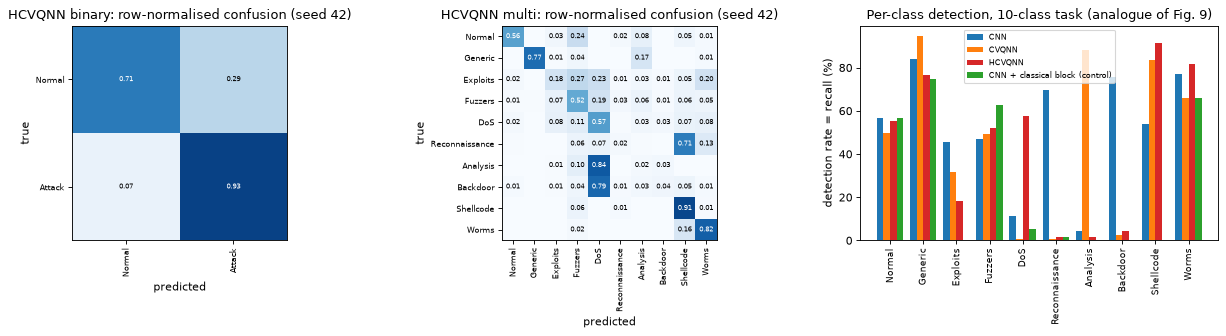

In [18]:
# Tables II and III analogues (test flows, natural class distribution)
ALL = RES[RES.protocol == "official"]
summ = ALL.groupby(["task", "model"])[["acc", "prec", "rec", "f1", "train_s", "params"]].agg(["mean", "std"]).round(2)
order = ["cnn", "cvqnn", "hcvqnn", "cnn_cls", "rf", "svc"]
for task in ("binary", "multi"):
    print("=== %s task, mean (std) over %d seeds ===" % (task, len(SEEDS)))
    t = summ.loc[task].reindex(order)
    print(pd.DataFrame({c: t[(c, "mean")].astype(str) + " (" + t[(c, "std")].fillna(0).astype(str) + ")" for c in ["acc", "prec", "rec", "f1"]}
                       | {"train_s": t[("train_s", "mean")], "params": t[("params", "mean")]}).to_string())
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
for a, (task, kind) in zip(ax[:2], (("binary", "hcvqnn"), ("multi", "hcvqnn"))):
    cm = ALL[(ALL.task == task) & (ALL.model == kind)].iloc[0]["cm"]
    cmn = cm / cm.sum(1, keepdims=True); labels = ["Normal", "Attack"] if task == "binary" else CLASSES
    im = a.imshow(cmn, cmap="Blues", vmin=0, vmax=1); a.set_xticks(range(len(labels))); a.set_yticks(range(len(labels)))
    a.set_xticklabels(labels, rotation=90, fontsize=7); a.set_yticklabels(labels, fontsize=7)
    a.set_title("HCVQNN %s: row-normalised confusion (seed %d)" % (task, SEEDS[0])); a.set_xlabel("predicted"); a.set_ylabel("true")
    for i in range(len(labels)):
        for j in range(len(labels)):
            if cmn[i, j] > 0.005: a.text(j, i, "%.2f" % cmn[i, j], ha="center", va="center", fontsize=6, color="white" if cmn[i, j] > 0.5 else "black")
w = 0.2
for k, kind in enumerate(["cnn", "cvqnn", "hcvqnn", "cnn_cls"]):
    R = np.mean([r for r in ALL[(ALL.task == "multi") & (ALL.model == kind)]["recall_per_class"]], 0)
    ax[2].bar(np.arange(10) + (k - 1.5) * w, R, w, color=STY[kind], label=NAMES[kind])
ax[2].set_xticks(range(10)); ax[2].set_xticklabels(CLASSES, rotation=90, fontsize=8); ax[2].set_ylabel("detection rate = recall (%)")
ax[2].set_title("Per-class detection, 10-class task (analogue of Fig. 9)"); ax[2].legend(fontsize=7); plt.tight_layout(); plt.show()

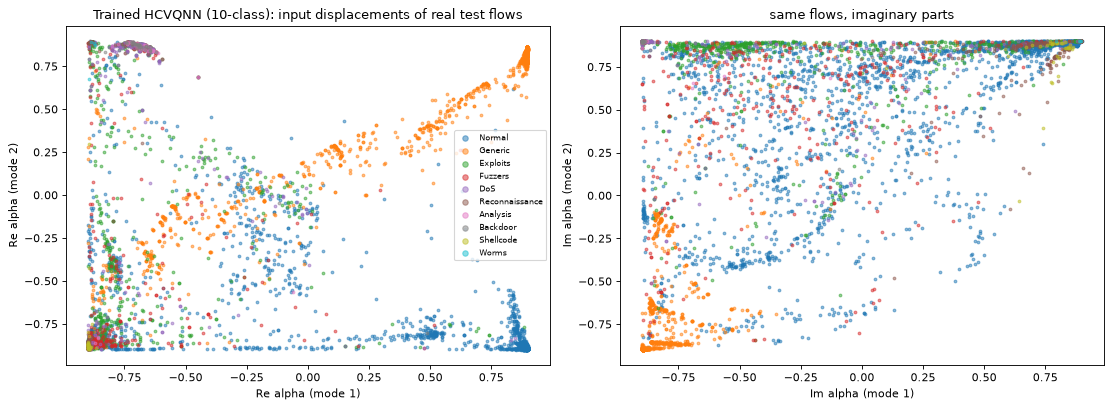

mean probability in the highest Fock level of either mode (truncation leakage): 8.79e-02
trained Gaussian circuit vs PennyLane, max |difference|: 1.45e-01
learned cubic-phase gammas per layer: [[0.082, 0.017], [0.039, 0.188]]


In [19]:
# What the trained CV layer sees: the learned input displacements for real test flows, coloured by true category
net = MODELS_TRAINED[("multi", "hcvqnn")]; net.eval()
sel = np.random.default_rng(1).choice(len(Xte), 6000, replace=False)
with torch.no_grad():
    al = net.alphas(torch.as_tensor(Xte[sel])).numpy()
fig, ax = plt.subplots(1, 2, figsize=(14, 5.2))
for i, c in enumerate(CLASSES):
    m = yte[sel] == i
    ax[0].scatter(al[m, 0].real, al[m, 1].real, s=6, alpha=0.5, color=COLORS[c], label=c)
    ax[1].scatter(al[m, 0].imag, al[m, 1].imag, s=6, alpha=0.5, color=COLORS[c])
ax[0].set_xlabel("Re alpha (mode 1)"); ax[0].set_ylabel("Re alpha (mode 2)"); ax[1].set_xlabel("Im alpha (mode 1)"); ax[1].set_ylabel("Im alpha (mode 2)")
ax[0].set_title("Trained HCVQNN (10-class): input displacements of real test flows"); ax[1].set_title("same flows, imaginary parts"); ax[0].legend(fontsize=7, markerscale=2)
plt.tight_layout(); plt.show()
# truncation leakage and Gaussian-part equivalence after training
with torch.no_grad():
    psi = encode(net.alphas(torch.as_tensor(Xte[sel[:2000]])))
    psi = psi.to(CS)
    for L in net.cv:
        psi = psi @ L.unitary().to(CS).T
    pr = (psi.real ** 2 + psi.imag ** 2).reshape(-1, CUTOFF, CUTOFF)
leak = (pr[:, -1, :].sum(1) + pr[:, :, -1].sum(1)).mean().item()
print("mean probability in the highest Fock level of either mode (truncation leakage): %.2e" % leak)
a = net.alphas(torch.as_tensor(Xte[:1]))[0].detach().numpy()
print("trained Gaussian circuit vs PennyLane, max |difference|: %.2e" % np.abs(fock_expectations(a, net.cv, True) - pl_expectations(a, list(net.cv))).max())
print("learned cubic-phase gammas per layer:", [np.round(L.nl.detach().numpy(), 3).tolist() for L in net.cv])

## 6. Sensitivity check: a pooled random split

The paper does not say how it split UNSW-NB15. The official partitions are known to be a hard, distribution-shifted benchmark (the testing partition contains attack types in different proportions), whereas a random split of the pooled flows is easier. This section repeats the whole experiment on a stratified 70/30 random split of the 257,673 pooled flows. It runs only when `RUN_RANDOM_PROTOCOL` is True (full mode).

In [20]:
if RUN_RANDOM_PROTOCOL:
    P2 = prepare("random", SEED)
    t_r = time.time()
    RES2, HIST2, _ = run_experiment(P2, RANDOM_PROTOCOL_SEEDS)
    print("random-split experiment: %.1f min" % ((time.time() - t_r) / 60))
    s2 = RES2.groupby(["task", "model"])[["acc", "prec", "rec", "f1"]].mean().round(2)
    print(s2.reindex(["cnn", "cvqnn", "hcvqnn", "cnn_cls", "rf", "svc"], level="model").to_string())
else:
    RES2 = None
    print("RUN_RANDOM_PROTOCOL is False (FAST_MODE): skipped. Set FAST_MODE = False for the pooled-random-split repetition.")

RUN_RANDOM_PROTOCOL is False (FAST_MODE): skipped. Set FAST_MODE = False for the pooled-random-split repetition.


## 7. Side by side with the paper

Verdict rule: a number is **reproduced** if it is within 2 percentage points of the paper, otherwise **not reached** (below) or **exceeded** (above), with the gap. Qualitative claims are checked on the mean over seeds. Primary results are on the official data partitions.

In [21]:
PAPER = {("binary", "cnn"): (92.70, 97.39, 90.50, 93.82), ("binary", "cvqnn"): (93.58, 97.38, 92.08, 94.65), ("binary", "hcvqnn"): (94.27, 98.36, 98.62, 95.68),
         ("multi", "cnn"): (81.34, 78.99, 81.34, 79.18), ("multi", "cvqnn"): (83.75, 84.67, 83.75, 82.59), ("multi", "hcvqnn"): (87.66, 88.76, 87.66, 86.29)}
def verdict(nb, paper, tol=2.0):
    d = nb - paper
    return "reproduced" if abs(d) <= tol else ("exceeded by %.1f" % d if d > 0 else "not reached (%.1f below)" % -d)
def compare(R, label):
    rows = []
    for (task, kind), vals in PAPER.items():
        sub = R[(R.task == task) & (R.model == kind)]
        for mname, pv in zip(["acc", "prec", "rec", "f1"], vals):
            mu, sd = sub[mname].mean(), sub[mname].std(ddof=0)
            rows.append(dict(split=label, task=task, model=NAMES[kind], metric=mname, paper=pv, notebook="%.2f +/- %.2f" % (mu, sd), verdict=verdict(mu, pv)))
    return pd.DataFrame(rows)
CMP = compare(RES[RES.protocol == "official"], "official")
if RES2 is not None:
    CMP = pd.concat([CMP, compare(RES2, "random 70/30")])
pd.set_option("display.width", 200, "display.max_rows", 200)
print(CMP.to_string(index=False))
print("\nverdict counts (official split):"); print(CMP[CMP.split == "official"]["verdict"].str.split(" ").str[0].value_counts().to_string())

   split   task  model metric  paper       notebook                  verdict
official binary    CNN    acc  92.70 82.79 +/- 0.00  not reached (9.9 below)
official binary    CNN   prec  97.39 78.74 +/- 0.00 not reached (18.6 below)
official binary    CNN    rec  90.50 94.17 +/- 0.00          exceeded by 3.7
official binary    CNN     f1  93.82 85.77 +/- 0.00  not reached (8.1 below)
official binary  CVQNN    acc  93.58 83.20 +/- 0.00 not reached (10.4 below)
official binary  CVQNN   prec  97.38 80.82 +/- 0.00 not reached (16.6 below)
official binary  CVQNN    rec  92.08 91.11 +/- 0.00               reproduced
official binary  CVQNN     f1  94.65 85.66 +/- 0.00  not reached (9.0 below)
official binary HCVQNN    acc  94.27 83.44 +/- 0.00 not reached (10.8 below)
official binary HCVQNN   prec  98.36 79.95 +/- 0.00 not reached (18.4 below)
official binary HCVQNN    rec  98.62 93.34 +/- 0.00  not reached (5.3 below)
official binary HCVQNN     f1  95.68 86.13 +/- 0.00  not reached (9.6 below)

In [22]:
# Qualitative claims
O = RES[RES.protocol == "official"]
mean = lambda t, m, c="acc": O[(O.task == t) & (O.model == m)][c].mean()
claims = []
for t in ("binary", "multi"):
    a = {m: mean(t, m) for m in ("cnn", "cvqnn", "hcvqnn")}
    claims.append(("R1 ranking HCVQNN > CVQNN > CNN accuracy, %s" % t, "HCVQNN %.2f, CVQNN %.2f, CNN %.2f" % (a["hcvqnn"], a["cvqnn"], a["cnn"]),
                   "reproduced" if a["hcvqnn"] > a["cvqnn"] > a["cnn"] else "not reached"))
    d = mean(t, "hcvqnn") - mean(t, "cnn_cls")
    claims.append(("(extra) CV layers vs classical block in the same network, %s accuracy" % t, "HCVQNN - control = %+.2f points" % d, "CV layer better" if d > 0.5 else ("no clear difference" if abs(d) <= 0.5 else "classical block better")))
    pe = {m: mean(t, m, "plateau_epoch") for m in ("cnn", "cvqnn", "hcvqnn")}; tl = {m: mean(t, m, "final_train_loss") for m in ("cnn", "cvqnn", "hcvqnn")}
    claims.append(("C1 HCVQNN converges fastest, %s" % t, "epochs to plateau: " + ", ".join("%s %.1f" % (NAMES[m], pe[m]) for m in pe),
                   "reproduced" if pe["hcvqnn"] <= min(pe.values()) else "not reached"))
    claims.append(("C1 HCVQNN reaches the lowest training loss, %s" % t, ", ".join("%s %.3f" % (NAMES[m], tl[m]) for m in tl), "reproduced" if tl["hcvqnn"] <= min(tl.values()) else "not reached"))
mi = [CLS_ID[c] for c in MINORITY]
pc = {m: np.mean([r for r in O[(O.task == "multi") & (O.model == m)]["recall_per_class"]], 0) for m in ("cnn", "cvqnn", "hcvqnn")}
claims.append(("D1 minority-class detection (mean recall of Analysis, Backdoor, Shellcode, Worms)", ", ".join("%s %.1f %%" % (NAMES[m], pc[m][mi].mean()) for m in pc),
               "reproduced" if pc["hcvqnn"][mi].mean() > max(pc["cnn"][mi].mean(), pc["cvqnn"][mi].mean()) else "not reached"))
claims.append(("D1 no class with detection rate 0 (HCVQNN, minimum class recall)", "min recall %.1f %% (%s)" % (pc["hcvqnn"].min(), CLASSES[int(pc["hcvqnn"].argmin())]), "reproduced" if pc["hcvqnn"].min() > 0 else "not reached"))
pp = {m: O[(O.task == "multi") & (O.model == m)]["params"].mean() for m in ("cnn", "hcvqnn")}; ts = {m: mean("multi", m, "train_s") for m in ("cnn", "hcvqnn")}
claims.append(("P1 fewer parameters than the classical network", "HCVQNN %d vs CNN %d trainable parameters" % (pp["hcvqnn"], pp["cnn"]), "reproduced" if pp["hcvqnn"] < pp["cnn"] else "not reached"))
claims.append(("P1 faster computation (abstract)", "train time per run: HCVQNN %.0f s vs CNN %.0f s (the CV layer is simulated on a classical CPU)" % (ts["hcvqnn"], ts["cnn"]),
               "cannot be checked on a simulator" if ts["hcvqnn"] > ts["cnn"] else "reproduced (simulated)"))
print(pd.DataFrame(claims, columns=["claim", "notebook", "verdict"]).to_string(index=False))
print("\nTotal notebook run time: %.1f min" % ((time.time() - NOTEBOOK_T0) / 60))

                                                                            claim                                                                                     notebook                verdict
                                 R1 ranking HCVQNN > CVQNN > CNN accuracy, binary                                                         HCVQNN 83.44, CVQNN 83.20, CNN 82.79             reproduced
        (extra) CV layers vs classical block in the same network, binary accuracy                                                              HCVQNN - control = -0.07 points    no clear difference
                                              C1 HCVQNN converges fastest, binary                                            epochs to plateau: CNN 4.0, CVQNN 6.0, HCVQNN 8.0            not reached
                               C1 HCVQNN reaches the lowest training loss, binary                                                         CNN 0.210, CVQNN 0.184, HCVQNN 0.239            not reached
          



Total notebook run time: 56.4 min


## Reading the paper critically

**What this run shows (FAST_MODE, one seed, official partitions).** Binary accuracy is 82.8 % (CNN), 83.2 % (CVQNN), 83.4 % (HCVQNN) against 92.7 / 93.6 / 94.3 % in the paper, and 10-class accuracy is 58.8 / 53.1 / 52.3 % against 81.3 / 83.8 / 87.7 %. The ordering HCVQNN > CVQNN > CNN holds for binary accuracy only by 0.2 to 0.4 points (a single seed, well inside the noise) and fails for 10 classes; Random Forest (83.7 % binary, 66.3 % 10-class) and RBF-SVM (86.0 % / 64.4 %) on the same 32 inputs beat every neural model. The validation accuracy of the same networks on held-out *training-partition* flows is about 91 % (binary), i.e. the 8-point drop on the official testing partition is the known distribution shift between the two partitions, not over-fitting to the balanced set alone; the paper's numbers are more in line with a random split of pooled flows (the full-mode repetition in Section 6, not run here). The 10-class budget (6,000 flows, 12 epochs) is also small, and the rarest class (Worms, about 117 real training flows) is stretched to 600 flows by Borderline-SMOTE.

**Caveats of the simulation.** After training, the mean probability in the top Fock level is 8.8 % and the Gaussian part of the trained circuit differs from PennyLane by up to 0.15 in a quadrature expectation: the learned circuit pushes the state against the cutoff, so the trained function is the *truncated* CV network (a larger `CUTOFF` or a smaller `ALPHA_MAX` would reduce this). The wall-clock times in the tables were measured on a CPU shared with many other jobs and vary by a factor of two between identical runs, so the "faster computation" line of the claims table must not be read as a measurement; the sound conclusion is that a classically simulated CV layer is not faster than the dense layer it replaces. The control network (classical block instead of the CV layers) is the fair test of the quantum component: it is within 0.1 points of HCVQNN for the binary task and 4.8 points *below* it for 10 classes in this single seed, which is suggestive of an optimisation-stability benefit but is not established without more seeds.


- **The data split and the balancing order are not stated.** If SMOTE and GMM resampling are applied to the whole data set *before* the train/test split (a common practice), synthetic neighbours of test flows leak into training and accuracies rise. Here balancing touches the training split only, the test set keeps the natural distribution, and a pooled-random-split repetition (full mode) shows how much the split alone matters.
- **Table II is internally inconsistent.** The HCVQNN row gives precision 98.36 % and recall 98.62 %; their harmonic mean is 98.49 %, not the reported F1 of 95.68 %. Recall (98.62 %) also exceeds accuracy (94.27 %) by more than the precision would allow for a two-class problem with comparable class sizes. Either a column is mislabelled or averaged differently, so those two cells cannot be checked meaningfully.
- **Recall equals accuracy in Table III**, which means support-weighted averaging; the notebook uses the same averaging.
- **One run, no variance.** The paper reports single curves. The gaps between CNN, CVQNN and HCVQNN (0.7 points binary, about 4 points 10-class) are of the size that a seed or a split changes. This notebook reports mean and standard deviation over seeds.
- **Is the "quantum" part doing the work?** The control network, identical except for a small classical block (Dense 4 - tanh - Dense 6 - tanh) in place of the two CV layers, answers this directly: see the extra row in the claims table. A 2-mode CV layer has only 16 parameters per layer; the CNN in front of it holds almost all of the capacity.
- **Cost claims.** The abstract motivates the work by fewer parameters and faster computation. A CV layer simulated in a truncated Fock space costs more than the dense layer it replaces; any speed-up would need photonic hardware, and none was run.
- **Truncation.** A cutoff-10 Fock simulation is only valid while the state stays well below the cutoff. The leakage printed after training quantifies this; the cubic phase gate in particular has an unbounded generator and is the first gate to violate a cutoff if its coefficient grows.
- **Table I ambiguity.** "Filter, stride, padding" for the max-pooling rows is read as pool size, stride, padding; the convolution kernel size is not given (3 here).

## Exercises

1. Set `NONGAUSSIAN = "kerr"` and compare accuracy and the learned gate strengths with the cubic phase gate.
2. Remove the non-Gaussian gate (`gaussian_only=True` in `CVLayer.unitary`). A purely Gaussian layer is, up to the encoding, a linear map of the quadratures followed by an exponential-type read-out; how much accuracy is lost?
3. Raise `CUTOFF` to 14 and `ALPHA_MAX` to 1.5. Does the truncation leakage grow, and does accuracy change?
4. Replace the `<x>, <p>, <n>` read-out by `<x>` and `<p>` only (4 numbers). What does the classifier lose?
5. Apply balancing to the pooled data before the split (this *leaks* synthetic neighbours). By how much do the accuracies rise, and why is that not a fair estimate of deployment performance?